# TransGeo — Disaster-specific similarity evaluation (Sample4Geo-aligned)

**Evaluation only.** Loads the existing CVIAN fine-tuned TransGeo checkpoint and reproduces the **exact six comparison groups** and presentation rules used in the latest Sample4Geo benchmark notebook.

| Matrix | Ground images | Satellite candidates | Expected direction |
|---|---|---|---|
| Flood — Positive | `Test_ground_image/Flood/` | Prefix `FLOOD` or `FLOODING` | Higher is better |
| Tsunami — Positive | `Test_ground_image/Tsunami/` | Prefix `TSUNAMI` | Higher is better |
| Cyclone — Positive | `Test_ground_image/Cyclone/` | Prefix `GABRIELLE_HAWKESBAY` / `CYCLONE` | Higher is better |
| Easy Negative | `Test_ground_image/easy_negative/` | First two satellite files alphabetically from **each** disaster group (six) | Lower is better |
| Random Negative | `Test_ground_image/random_negative/` | The same six satellites | Lower is better |
| Hard Negative | **Tsunami ground photos** (`Tsunami/`) | **Cyclone satellite images only** | Lower is better |

The obsolete `Test_ground_image/positive/` folder is intentionally ignored. Positive ground-truth pairs follow the Sample4Geo filename matching / manual override rules, and queries without a verified matching satellite are excluded from precision and confusion counts. The threshold is **cosine > 0.50**, not a calibrated probability.

**Output parity:** six similarity matrices, positive acceptance table, three per-disaster verified confusion matrices and precision summary, three negative-set FPRs plus a formatted FPR table, and an optional false-positive listing.

**Model-specific differences intentionally preserved:** TransGeo's query/reference transformer branches; ground `112×616`, satellite `256×256`; ImageNet normalization; 1000-dimensional descriptors; and the pre-existing fine-tuned checkpoint.


# 1. Configuration

The friend's fine-tuning notebook used the CVIAN TransGeo configuration with:

- ground input: **112 × 616**
- satellite input: **256 × 256**
- embedding dimension: **1000**
- ImageNet normalization

The evaluation notebook reconstructs the same TransGeo architecture and loads the saved `state_dict`.

In [26]:
from pathlib import Path
from types import SimpleNamespace
import sys
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from IPython.display import display

import torch
import torch.nn.functional as F
import torchvision.transforms as transforms


# ============================================================
# TRANSGEO REPOSITORY
# ============================================================

TRANSGEO_ROOT = Path(
    r"E:\python_project\Geo\transgeo"
)

if str(TRANSGEO_ROOT) not in sys.path:
    sys.path.insert(
        0,
        str(TRANSGEO_ROOT)
    )


# ============================================================
# IMPORT TRANSGEO ARCHITECTURE
# ============================================================

from model.TransGeo import TransGeo


# ============================================================
# FINE-TUNED MODEL WEIGHT DIRECTORY
# ============================================================

WEIGHTS_DIR = (
    TRANSGEO_ROOT
    / "weights"
    / "CVIAN"
)


# ============================================================
# CHECKPOINT SEARCH
#
# Preference:
# 1. model_best
# 2. latest checkpoint
# ============================================================

CHECKPOINT_CANDIDATES = [

    WEIGHTS_DIR
    / "model_best.pth.tar",

    WEIGHTS_DIR
    / "model_best.pth",

    WEIGHTS_DIR
    / "checkpoint.pth.tar",

    WEIGHTS_DIR
    / "checkpoint.pth",
]


print("Searching for TransGeo checkpoint:")
print()


for path in CHECKPOINT_CANDIDATES:

    if path.is_file():

        status = "FOUND"

    elif path.is_dir():

        status = "FOLDER - NOT A LOADABLE CHECKPOINT FILE"

    else:

        status = "not found"


    print(
        path,
        "->",
        status
    )


# ============================================================
# SELECT FIRST VALID CHECKPOINT FILE
# ============================================================

CHECKPOINT_PATH = next(

    (
        path

        for path
        in CHECKPOINT_CANDIDATES

        if path.is_file()
    ),

    None,
)


if CHECKPOINT_PATH is None:

    raise FileNotFoundError(
        "No valid TransGeo checkpoint file was found inside "
        f"{WEIGHTS_DIR}"
    )


print()
print(
    "Using checkpoint:",
    CHECKPOINT_PATH
)

# ============================================================
# SAME DATASET STRUCTURE AS SAMPLE4GEO
# ============================================================

GROUND_ROOT = Path(r"E:\python_project\Geo\Test_ground_image")
SATELLITE_FOLDER = Path(r"E:\python_project\Geo\Test_sat_image")

SATELLITE_CATEGORY_PREFIXES = {
    "Flood": ("FLOOD", "FLOODING"),
    "Tsunami": ("TSUNAMI",),
    "Cyclone": ("GABRIELLE_HAWKESBAY", "GABRIELE_HAWKESBAY", "CYCLONE"),
}
POSITIVE_CATEGORIES = ["Flood", "Tsunami", "Cyclone"]
NEGATIVE_TYPES = ["Easy Negative", "Random Negative", "Hard Negative"]
FIGURE_ORDER = POSITIVE_CATEGORIES + NEGATIVE_TYPES
NEGATIVE_SATELLITES_PER_CATEGORY = 2
HARD_NEGATIVE_GROUND_SOURCE = "Tsunami"

# ============================================================
# TRANSGEO DEVICE / MODEL SETTINGS (UNCHANGED)
# ============================================================
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = torch.cuda.is_available()
EMBEDDING_DIM = 1000
GROUND_SIZE = [112, 616]
SATELLITE_SIZE = [256, 256]
COSINE_THRESHOLD = 0.50
INFERENCE_BATCH_SIZE = 32
MODEL_LABEL = "TransGeo Fine-Tuned"

MODEL_REGISTRY = {
    "transgeo": {"label": MODEL_LABEL, "checkpoint": CHECKPOINT_PATH},
}
ACTIVE_MODEL_KEYS = ["transgeo"]

SAVE_FIGURES = False
FIGURE_OUTPUT_DIR = TRANSGEO_ROOT / "disaster_category_evaluation"
if SAVE_FIGURES:
    FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", sys.executable)
print("Device:", DEVICE)
print("Checkpoint:", CHECKPOINT_PATH)
print("Model selection:", ACTIVE_MODEL_KEYS)
print("Ground folder:", GROUND_ROOT)
print("Satellite folder:", SATELLITE_FOLDER)
print("Threshold: cosine >", COSINE_THRESHOLD)
print("Hard Negative ground source:", HARD_NEGATIVE_GROUND_SOURCE)


Searching for TransGeo checkpoint:

E:\python_project\Geo\transgeo\weights\CVIAN\model_best.pth.tar -> FOUND
E:\python_project\Geo\transgeo\weights\CVIAN\model_best.pth -> FOLDER - NOT A LOADABLE CHECKPOINT FILE
E:\python_project\Geo\transgeo\weights\CVIAN\checkpoint.pth.tar -> FOUND
E:\python_project\Geo\transgeo\weights\CVIAN\checkpoint.pth -> FOLDER - NOT A LOADABLE CHECKPOINT FILE

Using checkpoint: E:\python_project\Geo\transgeo\weights\CVIAN\model_best.pth.tar
Python: E:\python_project\Geo\Sample4Geo\Geo761\Scripts\python.exe
Device: cuda
Checkpoint: E:\python_project\Geo\transgeo\weights\CVIAN\model_best.pth.tar
Model selection: ['transgeo']
Ground folder: E:\python_project\Geo\Test_ground_image
Satellite folder: E:\python_project\Geo\Test_sat_image
Threshold: cosine > 0.5
Hard Negative ground source: Tsunami


# 2. Reconstruct TransGeo and load the fine-tuned checkpoint

The official TransGeo model contains separate **query** and **reference** transformer branches. The friend's CVIAN fine-tuning kept the CVUSA/CVACT input geometry, so this evaluation reconstructs the architecture with the same dimensions.

`dataset="cvusa"` is used only to instantiate the identical `112×616 / 256×256` architecture; the loaded checkpoint supplies the learned CVIAN fine-tuned weights.

In [27]:
model_args = SimpleNamespace(
    dim=EMBEDDING_DIM,
    dataset="cvusa",
    sat_res=0,
    fov=0,
    crop=False,
)


def extract_transgeo_state_dict(checkpoint):
    if not isinstance(checkpoint, dict):
        raise TypeError("Checkpoint is not a dictionary.")

    if "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    elif "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    else:
        state_dict = checkpoint

    cleaned = {}
    for key, value in state_dict.items():
        if key.startswith("module."):
            key = key[len("module."):]
        cleaned[key] = value

    return cleaned


transgeo_model = TransGeo(args=model_args)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False,
)

state_dict = extract_transgeo_state_dict(checkpoint)

load_result = transgeo_model.load_state_dict(
    state_dict,
    strict=True,
)

transgeo_model = transgeo_model.to(DEVICE)
transgeo_model.eval()

print("Checkpoint loaded successfully.")
print(load_result)

if isinstance(checkpoint, dict):
    if "epoch" in checkpoint:
        print("Checkpoint epoch:", checkpoint["epoch"])
    if "best_acc1" in checkpoint:
        print("Stored best_acc1:", checkpoint["best_acc1"])

Checkpoint loaded successfully.
<All keys matched successfully>
Checkpoint epoch: 10
Stored best_acc1: 37.6865671641791


# 3. TransGeo preprocessing

This matches the preprocessing used in the friend's CVIAN training notebook:

- resize ground → `112 × 616`
- resize satellite → `256 × 256`
- ImageNet mean/std normalization

In [28]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


def make_transform(size):
    return transforms.Compose([
        transforms.Resize(size=tuple(size)),
        transforms.ToTensor(),
        transforms.Normalize(
            mean=IMAGENET_MEAN,
            std=IMAGENET_STD,
        ),
    ])


ground_transform = make_transform(GROUND_SIZE)
satellite_transform = make_transform(SATELLITE_SIZE)

print("Ground transform size:", GROUND_SIZE)
print("Satellite transform size:", SATELLITE_SIZE)

Ground transform size: [112, 616]
Satellite transform size: [256, 256]


# 4. Discover disaster folders and categorize satellite images

All satellites remain in **one satellite folder**. Prefix-based grouping picks the correct set for each disaster. The two-satellite subset used for Easy and Random Negative is selected by **case-insensitive alphabetical filename order** within each category.

In [29]:
VALID_SUFFIXES = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".webp"}


def find_images(folder, recursive=False):
    if not folder.is_dir():
        return []
    files = folder.rglob("*") if recursive else folder.iterdir()
    return sorted(
        [p for p in files if p.is_file() and p.suffix.lower() in VALID_SUFFIXES],
        key=lambda p: (p.name.casefold(), str(p).casefold()),
    )


def normalized_name(filename):
    """Remove separator/case differences, leaving letters and numbers."""
    return re.sub(r"[^A-Z0-9]", "", Path(filename).stem.upper())


def assign_satellite_category(path):
    stem = normalized_name(path.name)
    matches = [
        cat for cat, prefixes in SATELLITE_CATEGORY_PREFIXES.items()
        if any(stem.startswith(normalized_name(prefix)) for prefix in prefixes)
    ]
    if len(matches) > 1:
        raise ValueError(f"Ambiguous satellite category for {path.name}: {matches}")
    return matches[0] if matches else None


satellite_files = find_images(SATELLITE_FOLDER)
if not satellite_files:
    raise FileNotFoundError(f"No satellite images found in {SATELLITE_FOLDER}")

satellite_by_category = {
    cat: [] for cat in POSITIVE_CATEGORIES
}
unknown_satellites = []
for path in satellite_files:
    cat = assign_satellite_category(path)
    if cat is None:
        unknown_satellites.append(path)
    else:
        satellite_by_category[cat].append(path)

# Sorting occurs alphabetically before selecting negative subsets.
negative_satellites = []
for cat in POSITIVE_CATEGORIES:
    group = satellite_by_category[cat]
    if len(group) < NEGATIVE_SATELLITES_PER_CATEGORY:
        raise ValueError(
            f"Need {NEGATIVE_SATELLITES_PER_CATEGORY} {cat} satellites, "
            f"but found {len(group)}. Check SATELLITE_CATEGORY_PREFIXES."
        )
    negative_satellites.extend(group[:NEGATIVE_SATELLITES_PER_CATEGORY])

positive_ground_paths = {
    cat: find_images(GROUND_ROOT / cat, recursive=True)
    for cat in POSITIVE_CATEGORIES
}

for cat in POSITIVE_CATEGORIES:
    if not positive_ground_paths[cat]:
        raise FileNotFoundError(f"No {cat} ground photos found under {GROUND_ROOT / cat}")
    if not satellite_by_category[cat]:
        raise ValueError(f"No {cat} satellite candidates found")

negative_ground_paths = {
    "Easy Negative": find_images(GROUND_ROOT / "easy_negative", recursive=True),
    "Random Negative": find_images(GROUND_ROOT / "random_negative", recursive=True),
    "Hard Negative": find_images(GROUND_ROOT / HARD_NEGATIVE_GROUND_SOURCE, recursive=True),
}

for name, paths in negative_ground_paths.items():
    if not paths:
        raise FileNotFoundError(f"No ground photos found for {name}")

# These six comparisons are the *only* pair groups for inference.
# Ground and satellite filenames are maintained exactly as provided.
EVALUATION_GROUPS = {
    cat: {
        "ground_paths": positive_ground_paths[cat],
        "satellite_paths": satellite_by_category[cat],
        "is_positive": True,
    }
    for cat in POSITIVE_CATEGORIES
}
EVALUATION_GROUPS["Easy Negative"] = {
    "ground_paths": negative_ground_paths["Easy Negative"],
    "satellite_paths": negative_satellites,
    "is_positive": False,
}
EVALUATION_GROUPS["Random Negative"] = {
    "ground_paths": negative_ground_paths["Random Negative"],
    "satellite_paths": negative_satellites,
    "is_positive": False,
}
EVALUATION_GROUPS["Hard Negative"] = {
    "ground_paths": negative_ground_paths["Hard Negative"],
    "satellite_paths": satellite_by_category["Cyclone"],
    "is_positive": False,
}

print("DISASTER-SPECIFIC SATELLITE INVENTORY")
for category in POSITIVE_CATEGORIES:
    print()
    print(category, "satellites:", len(satellite_by_category[category]))
    for path in satellite_by_category[category]:
        print("  ", path.name)

print()
print("EASY / RANDOM NEGATIVE: FIRST 2 ALPHABETICALLY FROM EACH CATEGORY")
for category in POSITIVE_CATEGORIES:
    print(category)
    for path in satellite_by_category[category][:NEGATIVE_SATELLITES_PER_CATEGORY]:
        print("  ", path.name)

print()
print("HARD NEGATIVE: ground from", HARD_NEGATIVE_GROUND_SOURCE)
print("HARD NEGATIVE: satellites from Cyclone")

print()
print("EVALUATION GROUP COUNTS")
summary_rows = []
for group_name in FIGURE_ORDER:
    group = EVALUATION_GROUPS[group_name]
    summary_rows.append({
        "Figure": group_name,
        "Ground images": len(group["ground_paths"]),
        "Satellite images": len(group["satellite_paths"]),
        "Total pairs": len(group["ground_paths"]) * len(group["satellite_paths"]),
    })
display(pd.DataFrame(summary_rows))

if unknown_satellites:
    print()
    print("Unrecognized satellite filenames (ignored):")
    for path in unknown_satellites:
        print(" -", path.name)

DISASTER-SPECIFIC SATELLITE INVENTORY

Flood satellites: 4
   FLOODING_FLORIDA_SAT.jpeg
   FLOODING_LIBYA_SAT.jpeg
   FLOODING_LUGANVILLE_SAT.jpeg
   FLOODING_NATHAMAKI_SAT.jpeg

Tsunami satellites: 3
   TSUNAMI_NUKU'ALOFA_SAT.jpg
   TSUNAMI_PALU_SAT.jpg
   TSUNAMI_PALU_SAT2.jpg

Cyclone satellites: 5
   GABRIELLE_HAWKESBAY_SAT1.png
   GABRIELLE_HAWKESBAY_SAT2.png
   GABRIELLE_HAWKESBAY_SAT3.png
   GABRIELLE_HAWKESBAY_SAT4.png
   GABRIELLE_HAWKESBAY_SAT5.png

EASY / RANDOM NEGATIVE: FIRST 2 ALPHABETICALLY FROM EACH CATEGORY
Flood
   FLOODING_FLORIDA_SAT.jpeg
   FLOODING_LIBYA_SAT.jpeg
Tsunami
   TSUNAMI_NUKU'ALOFA_SAT.jpg
   TSUNAMI_PALU_SAT.jpg
Cyclone
   GABRIELLE_HAWKESBAY_SAT1.png
   GABRIELLE_HAWKESBAY_SAT2.png

HARD NEGATIVE: ground from Tsunami
HARD NEGATIVE: satellites from Cyclone

EVALUATION GROUP COUNTS


,Figure,Ground images,Satellite images,Total pairs
0,Flood,4,4,16
1,Tsunami,3,3,9
2,Cyclone,5,5,25
3,Easy Negative,4,6,24
4,Random Negative,4,6,24
5,Hard Negative,3,5,15



Unrecognized satellite filenames (ignored):
 - Gabrielle_Sample4Geo_Heatmap.png
 - LongBay_SAT.jpg
 - Okura_SAT.jpg
 - RodneyWard_SAT.jpg


# 5. Optional filename-based true-pair mapping for the positive confusion matrix

The matrices compare all images **within the requested disaster category**, but actual geographic correspondence is more specific. For example, a Florida flood photograph need not match a Libya flood satellite.

The helper below tries to map positive pairs by **base name** and, where present, an indexed ground suffix `_<number>` to the same `SAT<number>` satellite. Differences in spaces, underscores, and case are ignored. You can add mappings in `MANUAL_POSITIVE_MATCHES` for filenames that do not follow this rule.

**Unmatched positive ground photos are excluded from precision/confusion counts and reported separately.** Their similarity scores remain in the heatmaps and positive acceptance table. This avoids assigning false labels when filenames alone do not establish the correct location.

In [30]:
# Add exact per-image mappings here if the automatic match preview is incomplete.
# Example: "GABRIELLE_HAWKESBAY_1.png": ["GABRIELLE_HAWKESBAY_SAT1.png"]
MANUAL_POSITIVE_MATCHES = {
}


def normalize_stem(filename):
    return re.sub(r"[^A-Z0-9]+", "_", Path(filename).stem.upper()).strip("_")


def ground_match_parts(filename):
    stem = normalize_stem(filename)
    stem = re.sub(r"_(LEFT|RIGHT|CROSSV|CROSSVIEW|GROUND|IMG|IMAGE)$", "", stem)
    match = re.search(r"_(\d+)$", stem)
    if match:
        sample_num = int(match.group(1))
        stem = stem[:match.start()]
    else:
        sample_num = None
    return (re.sub(r"[^A-Z0-9]", "", stem), sample_num)


def satellite_match_parts(filename):
    stem = normalize_stem(filename)
    match = re.search(r"_(SATELLITE|SAT)(\d*)$", stem)
    if match:
        sample_num = int(match.group(2)) if match.group(2) else None
        stem = stem[:match.start()]
    else:
        sample_num = None
    return (re.sub(r"[^A-Z0-9]", "", stem), sample_num)


def infer_positive_satellites(ground_name, candidates):
    candidate_names = {p.name for p in candidates}
    if ground_name in MANUAL_POSITIVE_MATCHES:
        specified = MANUAL_POSITIVE_MATCHES[ground_name]
        missing = sorted(set(specified) - candidate_names)
        if missing:
            raise ValueError(f"Manual matches for {ground_name} not in selected satellite group: {missing}")
        return [name for name in specified if name in candidate_names]

    g_base, g_index = ground_match_parts(ground_name)
    matched = []
    for candidate in candidates:
        s_base, s_index = satellite_match_parts(candidate.name)
        if g_base == s_base and (g_index is None or g_index == s_index):
            matched.append(candidate.name)
    return matched


MATCHED_POSITIVE_SATELLITES = {}
verification_rows = []

for category in POSITIVE_CATEGORIES:
    satellites = EVALUATION_GROUPS[category]["satellite_paths"]
    for ground in EVALUATION_GROUPS[category]["ground_paths"]:
        # A pair of (category, path) keys prevents collisions from equal filenames in folders.
        pair_key = (category, str(ground))
        matches = infer_positive_satellites(ground.name, satellites)
        MATCHED_POSITIVE_SATELLITES[pair_key] = matches
        verification_rows.append({
            "Category": category,
            "Ground image": ground.name,
            "Match count": len(matches),
            "Matched satellite(s)": ", ".join(matches) if matches else "UNVERIFIED",
        })

print("POSITIVE FILENAME-BASED PAIR VERIFICATION")
match_preview = pd.DataFrame(verification_rows)
display(match_preview)
print()
print("FULL MATCH LIST (not truncated):")
for row in verification_rows:
    print(row["Category"], "|", row["Ground image"], "->", row["Matched satellite(s)"])

unverified_count = int((match_preview["Match count"] == 0).sum())
if unverified_count:
    warnings.warn(
        f"{unverified_count} positive ground photo(s) have NO verified satellite "
        "match. Similarity matrices will still include them; filename-based "
        "precision/confusion will exclude their rows. Add manual matches if available."
    )

POSITIVE FILENAME-BASED PAIR VERIFICATION


,Category,Ground image,Match count,Matched satellite(s)
0,Flood,FLOODING_FLORIDA.jpg,1,FLOODING_FLORIDA_SAT.jpeg
1,Flood,FLOODING_LIBYA.jpeg,1,FLOODING_LIBYA_SAT.jpeg
2,Flood,FLOODING_LUGANVILLE.jpeg,1,FLOODING_LUGANVILLE_SAT.jpeg
3,Flood,FLOODING_NATHAMAKI.jpg,1,FLOODING_NATHAMAKI_SAT.jpeg
4,Tsunami,TSUNAMI_NUKU'ALOFA.jpg,1,TSUNAMI_NUKU'ALOFA_SAT.jpg
5,Tsunami,TSUNAMI_PALU.jpg,2,"TSUNAMI_PALU_SAT.jpg, TSUNAMI_PALU_SAT2.jpg"
6,Tsunami,TSUNAMI_PALU2.jpeg,0,UNVERIFIED
7,Cyclone,GABRIELLE_HAWKESBAY_1.png,1,GABRIELLE_HAWKESBAY_SAT1.png
8,Cyclone,GABRIELLE_HAWKESBAY_2.PNG,1,GABRIELLE_HAWKESBAY_SAT2.png
9,Cyclone,GABRIELLE_HAWKESBAY_3.PNG,1,GABRIELLE_HAWKESBAY_SAT3.png



FULL MATCH LIST (not truncated):
Flood | FLOODING_FLORIDA.jpg -> FLOODING_FLORIDA_SAT.jpeg
Flood | FLOODING_LIBYA.jpeg -> FLOODING_LIBYA_SAT.jpeg
Flood | FLOODING_LUGANVILLE.jpeg -> FLOODING_LUGANVILLE_SAT.jpeg
Flood | FLOODING_NATHAMAKI.jpg -> FLOODING_NATHAMAKI_SAT.jpeg
Tsunami | TSUNAMI_NUKU'ALOFA.jpg -> TSUNAMI_NUKU'ALOFA_SAT.jpg
Tsunami | TSUNAMI_PALU.jpg -> TSUNAMI_PALU_SAT.jpg, TSUNAMI_PALU_SAT2.jpg
Tsunami | TSUNAMI_PALU2.jpeg -> UNVERIFIED
Cyclone | GABRIELLE_HAWKESBAY_1.png -> GABRIELLE_HAWKESBAY_SAT1.png
Cyclone | GABRIELLE_HAWKESBAY_2.PNG -> GABRIELLE_HAWKESBAY_SAT2.png
Cyclone | GABRIELLE_HAWKESBAY_3.PNG -> GABRIELLE_HAWKESBAY_SAT3.png
Cyclone | GABRIELLE_HAWKESBAY_4.png -> GABRIELLE_HAWKESBAY_SAT4.png
Cyclone | GABRIELLE_HAWKESBAY_5.png -> GABRIELLE_HAWKESBAY_SAT5.png


C:\Users\sifat\AppData\Local\Temp\ipykernel_150768\1185915337.py:79: UserWarning: 1 positive ground photo(s) have NO verified satellite match. Similarity matrices will still include them; filename-based precision/confusion will exclude their rows. Add manual matches if available.
  warnings.warn(


# 6. Run feature extraction and calculate only the requested ground–satellite comparisons

In [31]:
def embed_ground_paths(model, paths, batch_size=32):
    """Use TransGeo's query_net on ground photos, with its original transform."""
    if not paths:
        raise ValueError("Cannot embed an empty ground image list")
    embeddings = []
    model.eval()
    with torch.inference_mode():
        for start in range(0, len(paths), batch_size):
            tensors = []
            for path in paths[start:start + batch_size]:
                with Image.open(path) as image:
                    tensors.append(ground_transform(image.convert("RGB")))
            batch = torch.stack(tensors).to(DEVICE, non_blocking=True)
            with torch.amp.autocast(device_type="cuda", enabled=USE_AMP):
                features = model.query_net(batch)
            embeddings.append(F.normalize(features.float(), p=2, dim=1).cpu())
    return torch.cat(embeddings, dim=0)


def embed_satellite_paths(model, paths, batch_size=32):
    """Use TransGeo's reference_net on satellite photos, with its original transform."""
    if not paths:
        raise ValueError("Cannot embed an empty satellite image list")
    embeddings = []
    model.eval()
    with torch.inference_mode():
        for start in range(0, len(paths), batch_size):
            tensors = []
            for path in paths[start:start + batch_size]:
                with Image.open(path) as image:
                    tensors.append(satellite_transform(image.convert("RGB")))
            batch = torch.stack(tensors).to(DEVICE, non_blocking=True)
            with torch.amp.autocast(device_type="cuda", enabled=USE_AMP):
                features = model.reference_net(x=batch, indexes=None)
            embeddings.append(F.normalize(features.float(), p=2, dim=1).cpu())
    return torch.cat(embeddings, dim=0)


def run_model_similarity(model_key, model):
    """Same six sets, same pair keys/column schema as Sample4Geo."""
    print("Computing embeddings for:", MODEL_REGISTRY[model_key]["label"])
    all_ground = sorted(
        {p for group in EVALUATION_GROUPS.values() for p in group["ground_paths"]},
        key=lambda p: str(p).casefold(),
    )
    all_satellite = sorted(
        {p for group in EVALUATION_GROUPS.values() for p in group["satellite_paths"]},
        key=lambda p: str(p).casefold(),
    )
    ground_emb = embed_ground_paths(model, all_ground, INFERENCE_BATCH_SIZE)
    sat_emb = embed_satellite_paths(model, all_satellite, INFERENCE_BATCH_SIZE)
    ground_index = {p: i for i, p in enumerate(all_ground)}
    sat_index = {p: j for j, p in enumerate(all_satellite)}
    scores = (ground_emb @ sat_emb.T).numpy()

    rows = []
    for group_name in FIGURE_ORDER:
        group = EVALUATION_GROUPS[group_name]
        for ground in group["ground_paths"]:
            for sat in group["satellite_paths"]:
                rows.append({
                    "model_key": model_key,
                    "model_label": MODEL_REGISTRY[model_key]["label"],
                    "query_type": group_name,
                    "ground_path": str(ground),
                    "ground_image": ground.name,
                    "satellite_image": sat.name,
                    "cosine_similarity": float(scores[ground_index[ground], sat_index[sat]]),
                    "is_positive_group": group["is_positive"],
                })
    return pd.DataFrame(rows)


# One fine-tuned TransGeo model. Keep dictionary for report-ready parity.
models = {"transgeo": transgeo_model}
all_similarity_frames = [
    run_model_similarity(key, models[key]) for key in ACTIVE_MODEL_KEYS
]
similarity_raw = pd.concat(all_similarity_frames, ignore_index=True)

print("Similarity inference finished.")
print("Total evaluated pairs:", len(similarity_raw))
display(similarity_raw.head())


Computing embeddings for: TransGeo Fine-Tuned
Similarity inference finished.
Total evaluated pairs: 113


,model_key,model_label,query_type,ground_path,ground_image,satellite_image,cosine_similarity,is_positive_group
0,transgeo,TransGeo Fine-Tuned,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_FLORIDA_SAT.jpeg,0.536072,True
1,transgeo,TransGeo Fine-Tuned,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_LIBYA_SAT.jpeg,0.464224,True
2,transgeo,TransGeo Fine-Tuned,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_LUGANVILLE_SAT.jpeg,0.551065,True
3,transgeo,TransGeo Fine-Tuned,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_NATHAMAKI_SAT.jpeg,0.479808,True
4,transgeo,TransGeo Fine-Tuned,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_LIBYA.jpeg,FLOODING_FLORIDA_SAT.jpeg,0.557137,True


# 7. Six publication-style similarity matrices per enabled model

- **Positive (Flood, Tsunami, Cyclone):** yellow → light green → green; *higher is better*.
- **Negative (Easy, Random, Hard):** light orange → orange → red; *lower is better*.
- A score **strictly greater than 0.50** is printed in **larger, bold, pure black text** in both types.
- Color scale stays fixed from −1 to +1 (the valid cosine range) across all six figures for honest visual comparisons.

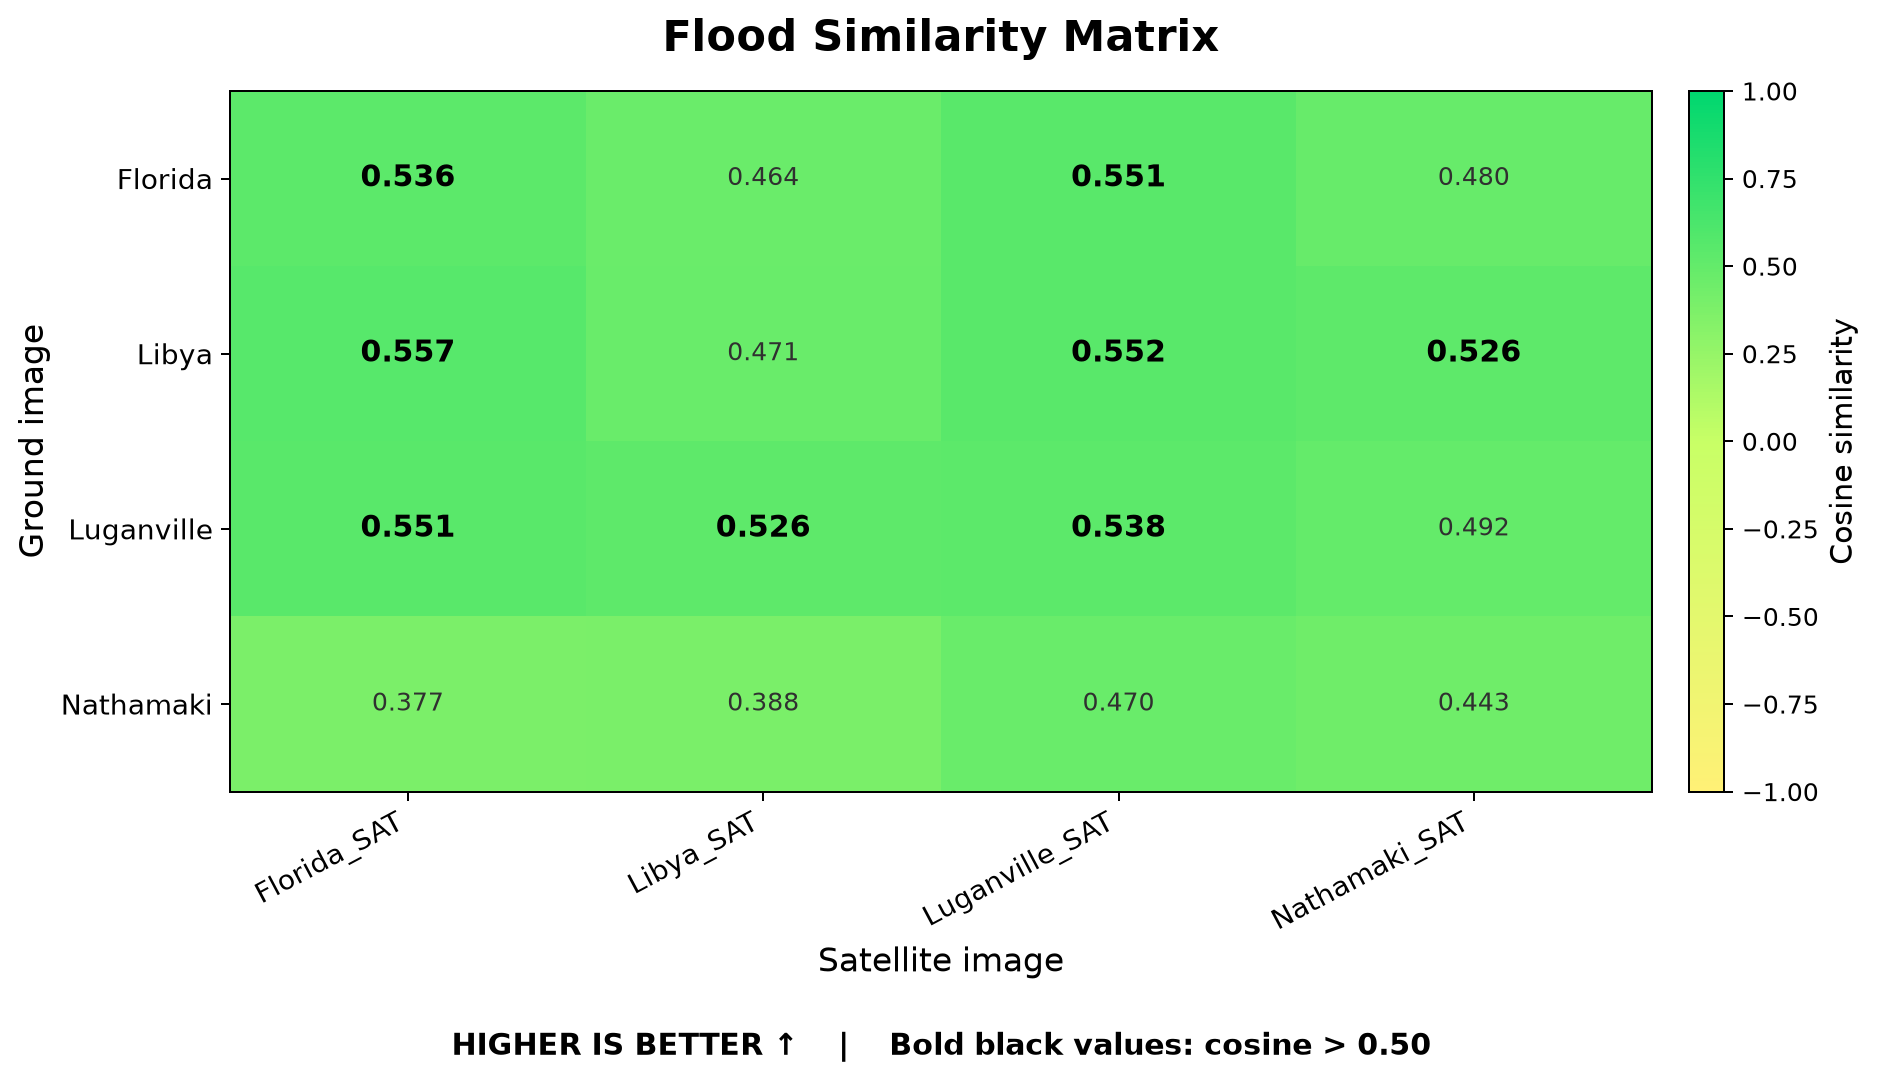

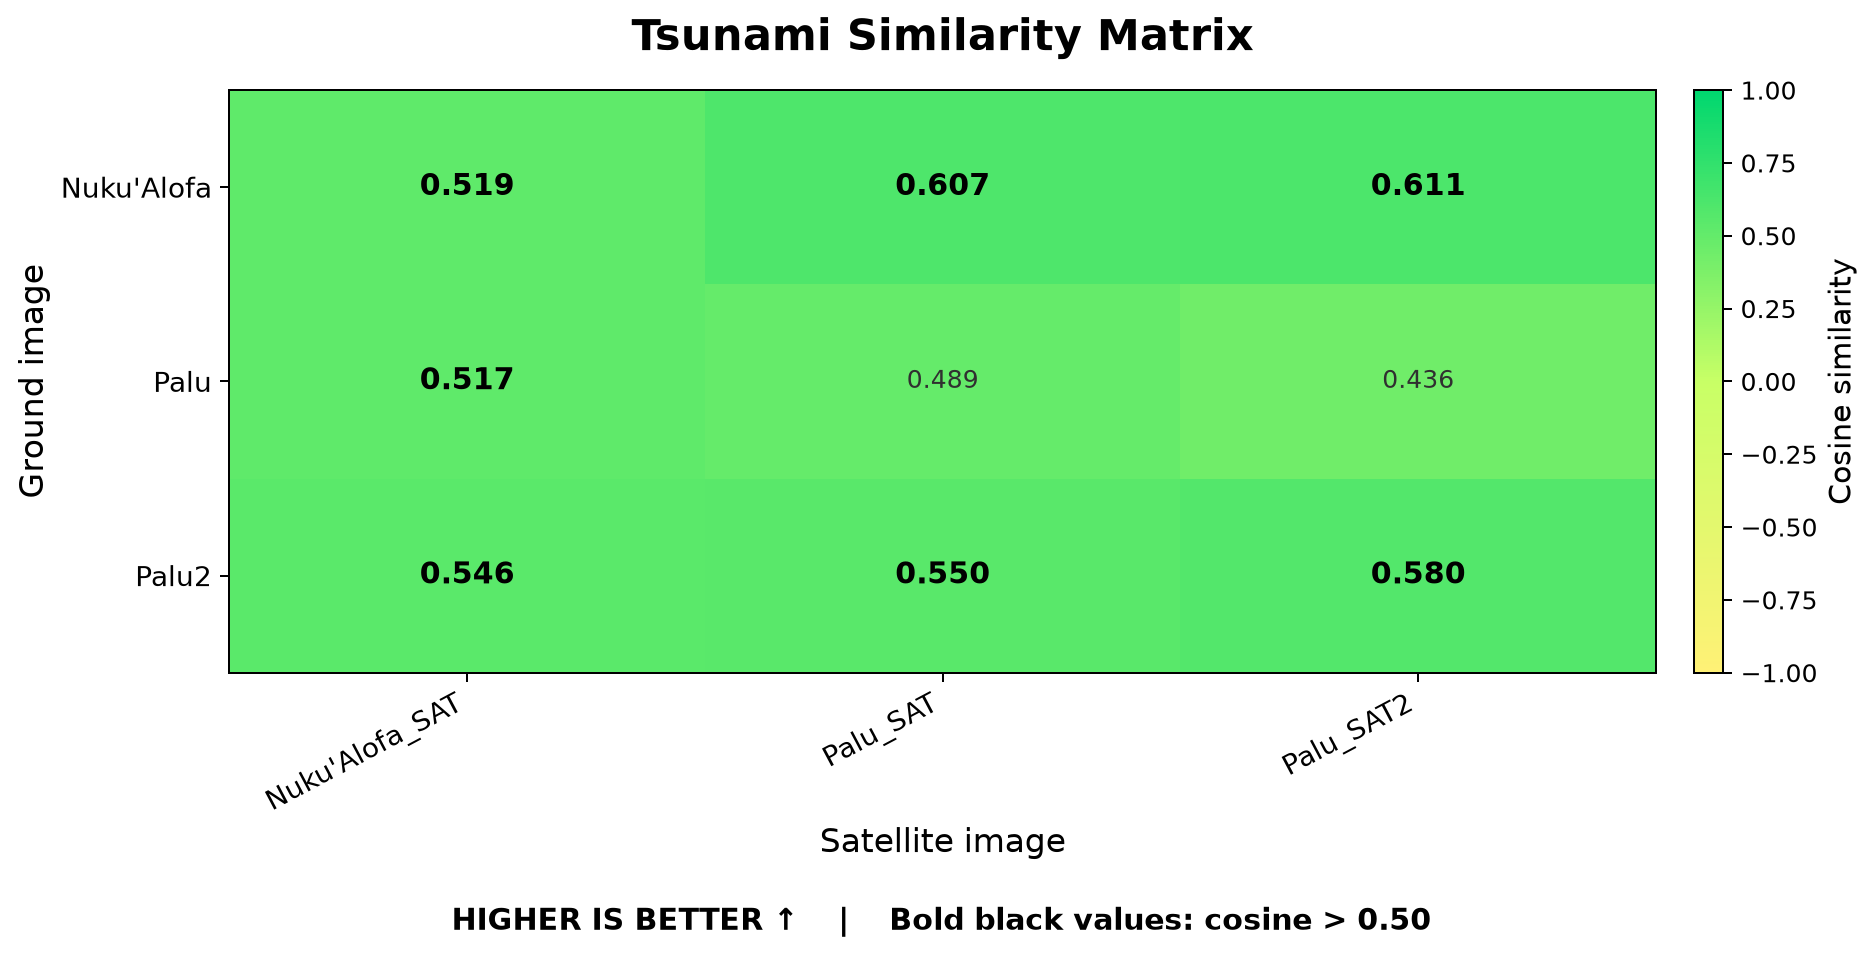

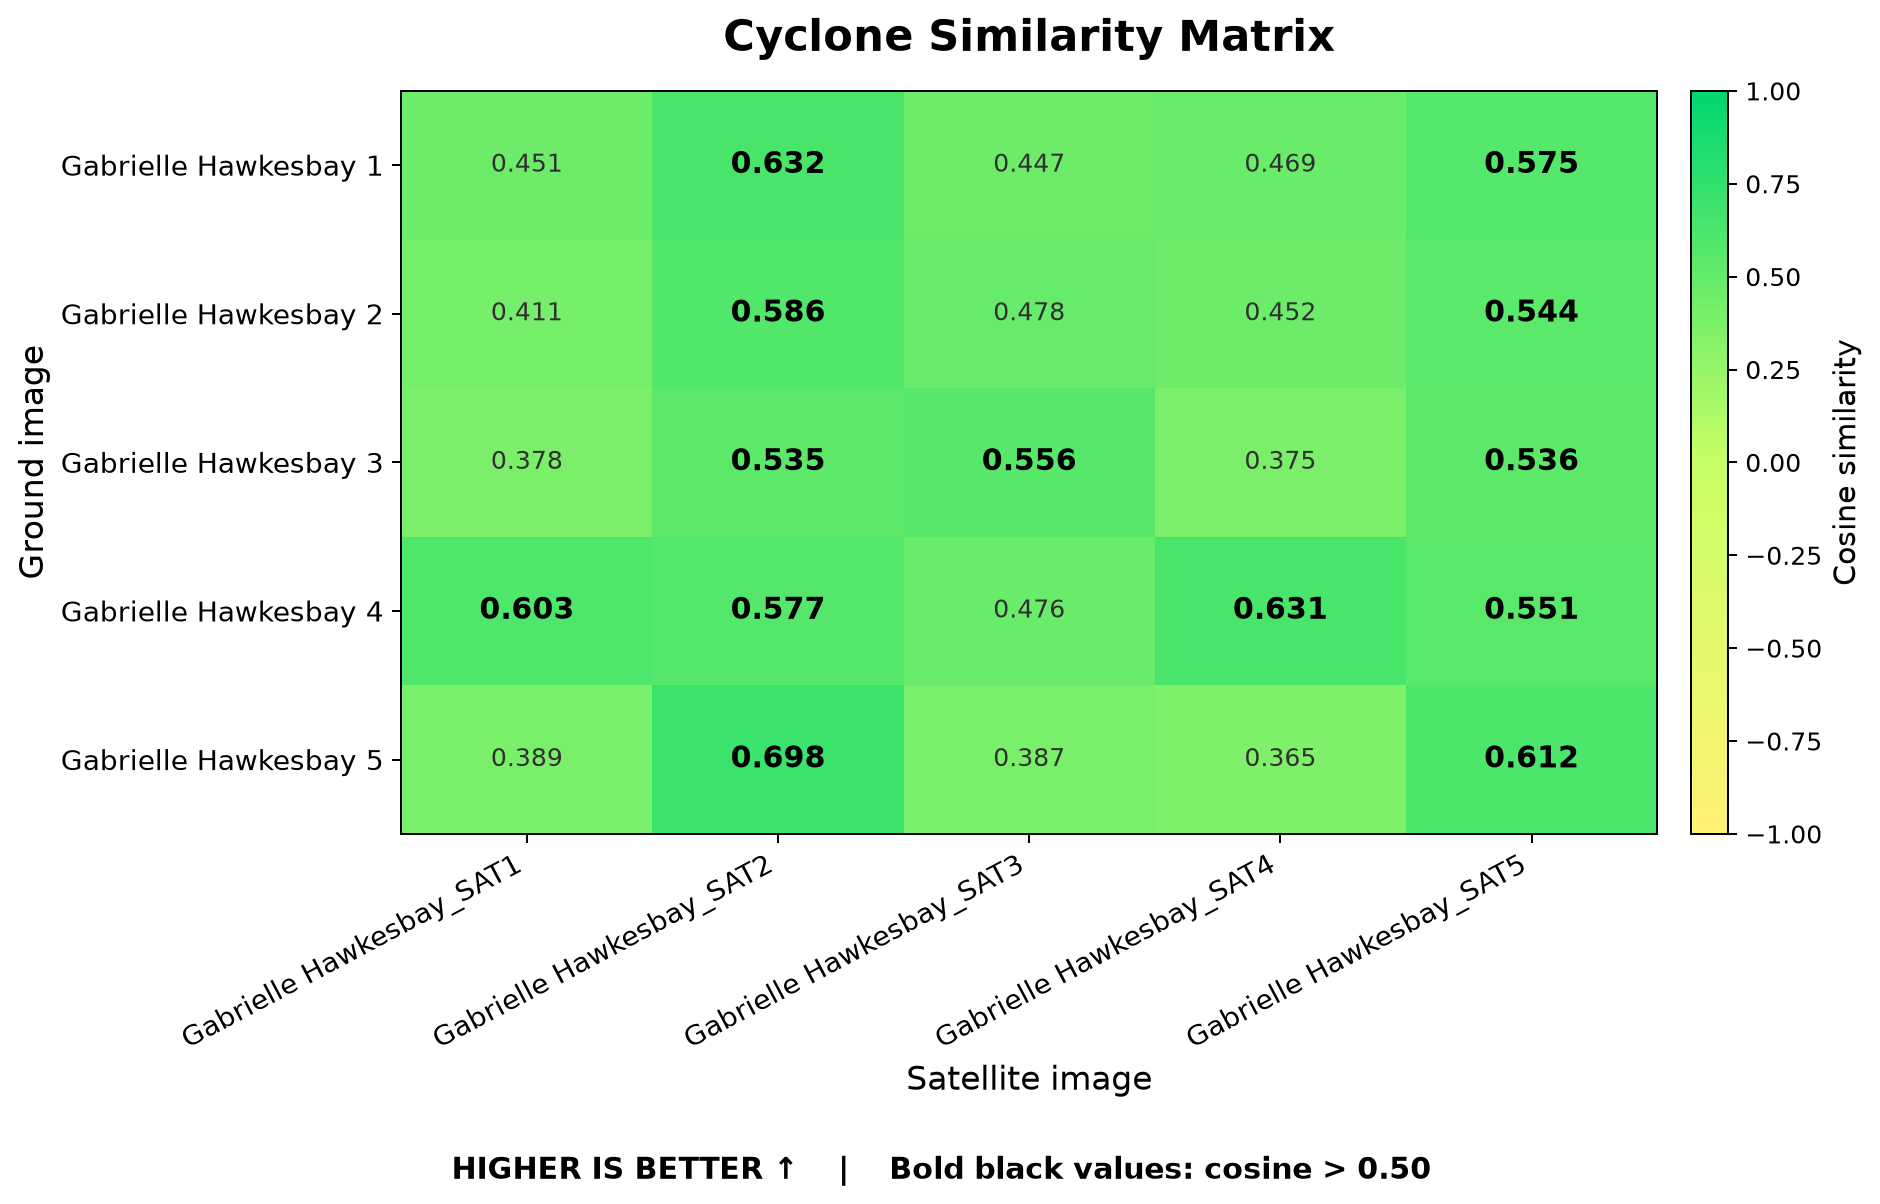

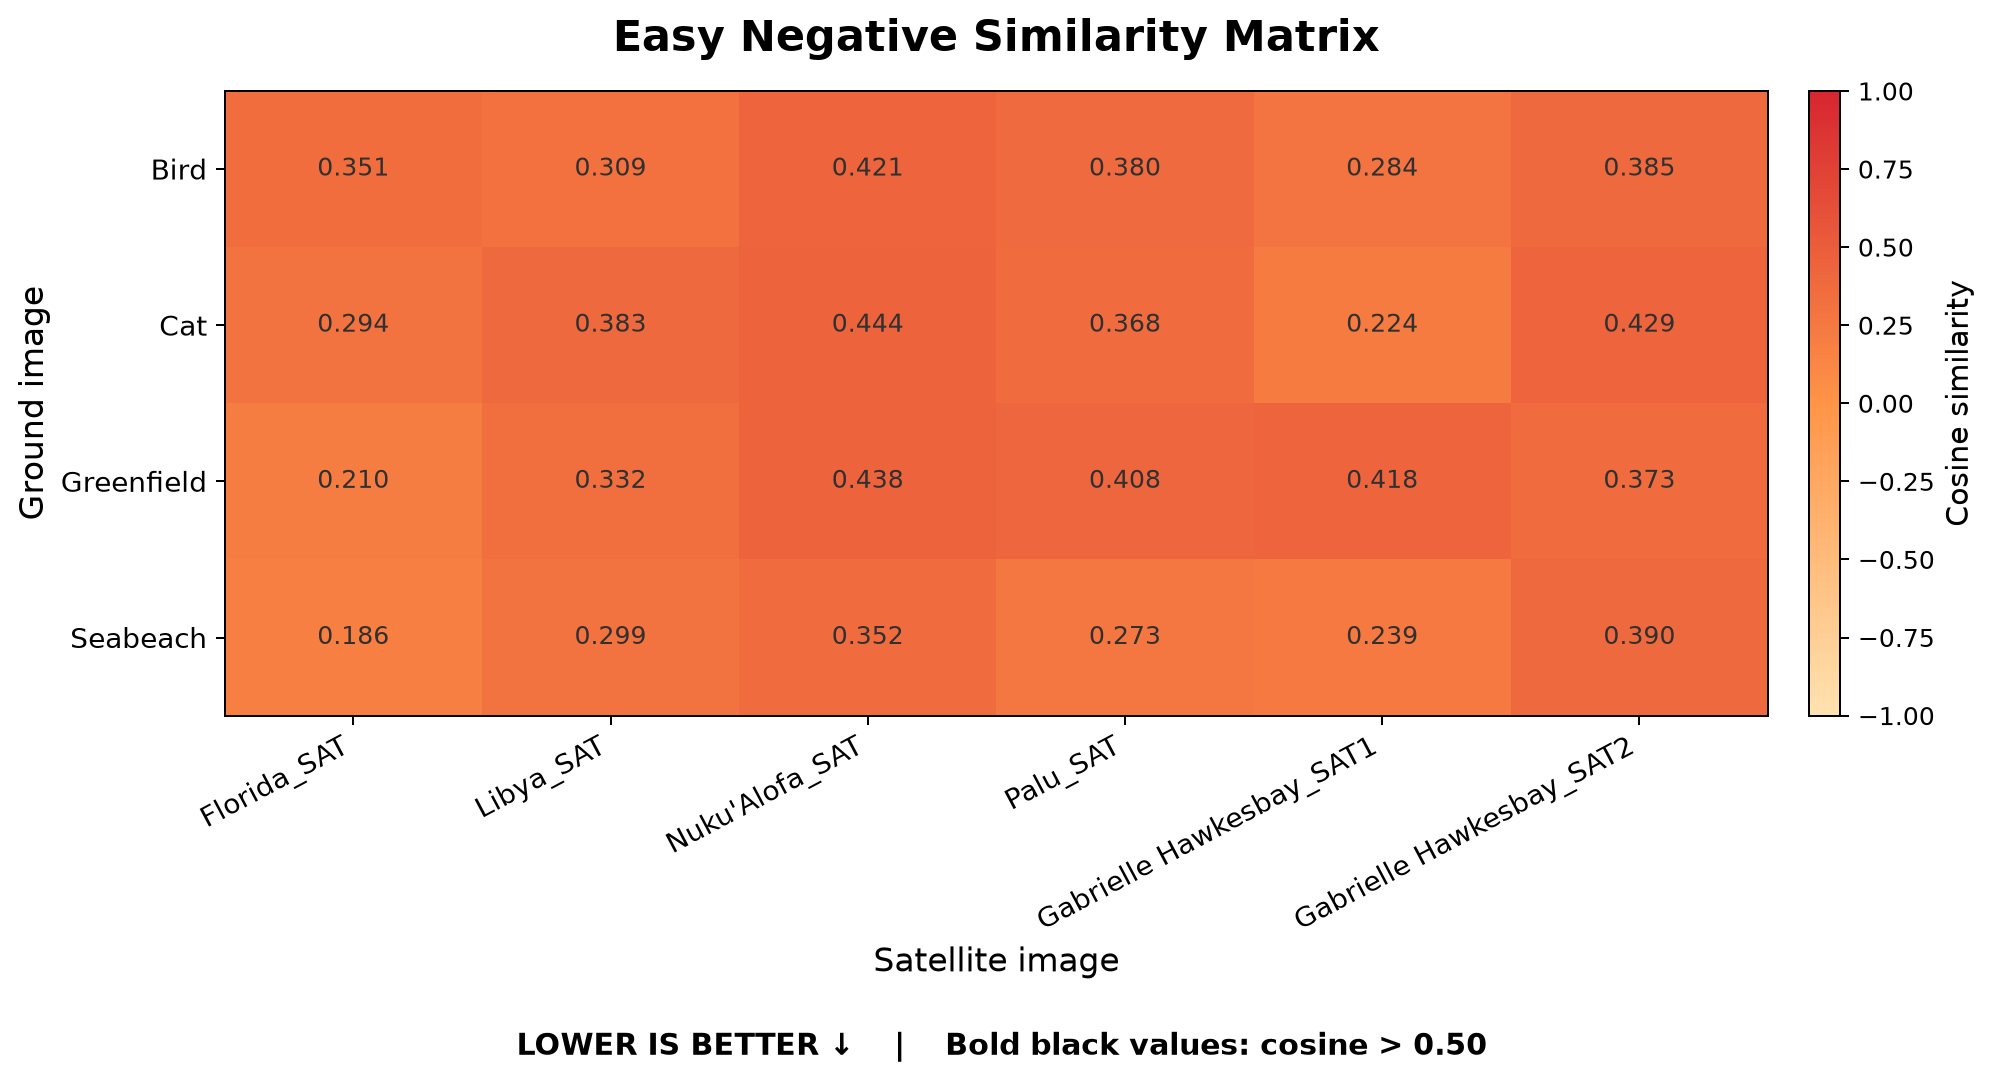

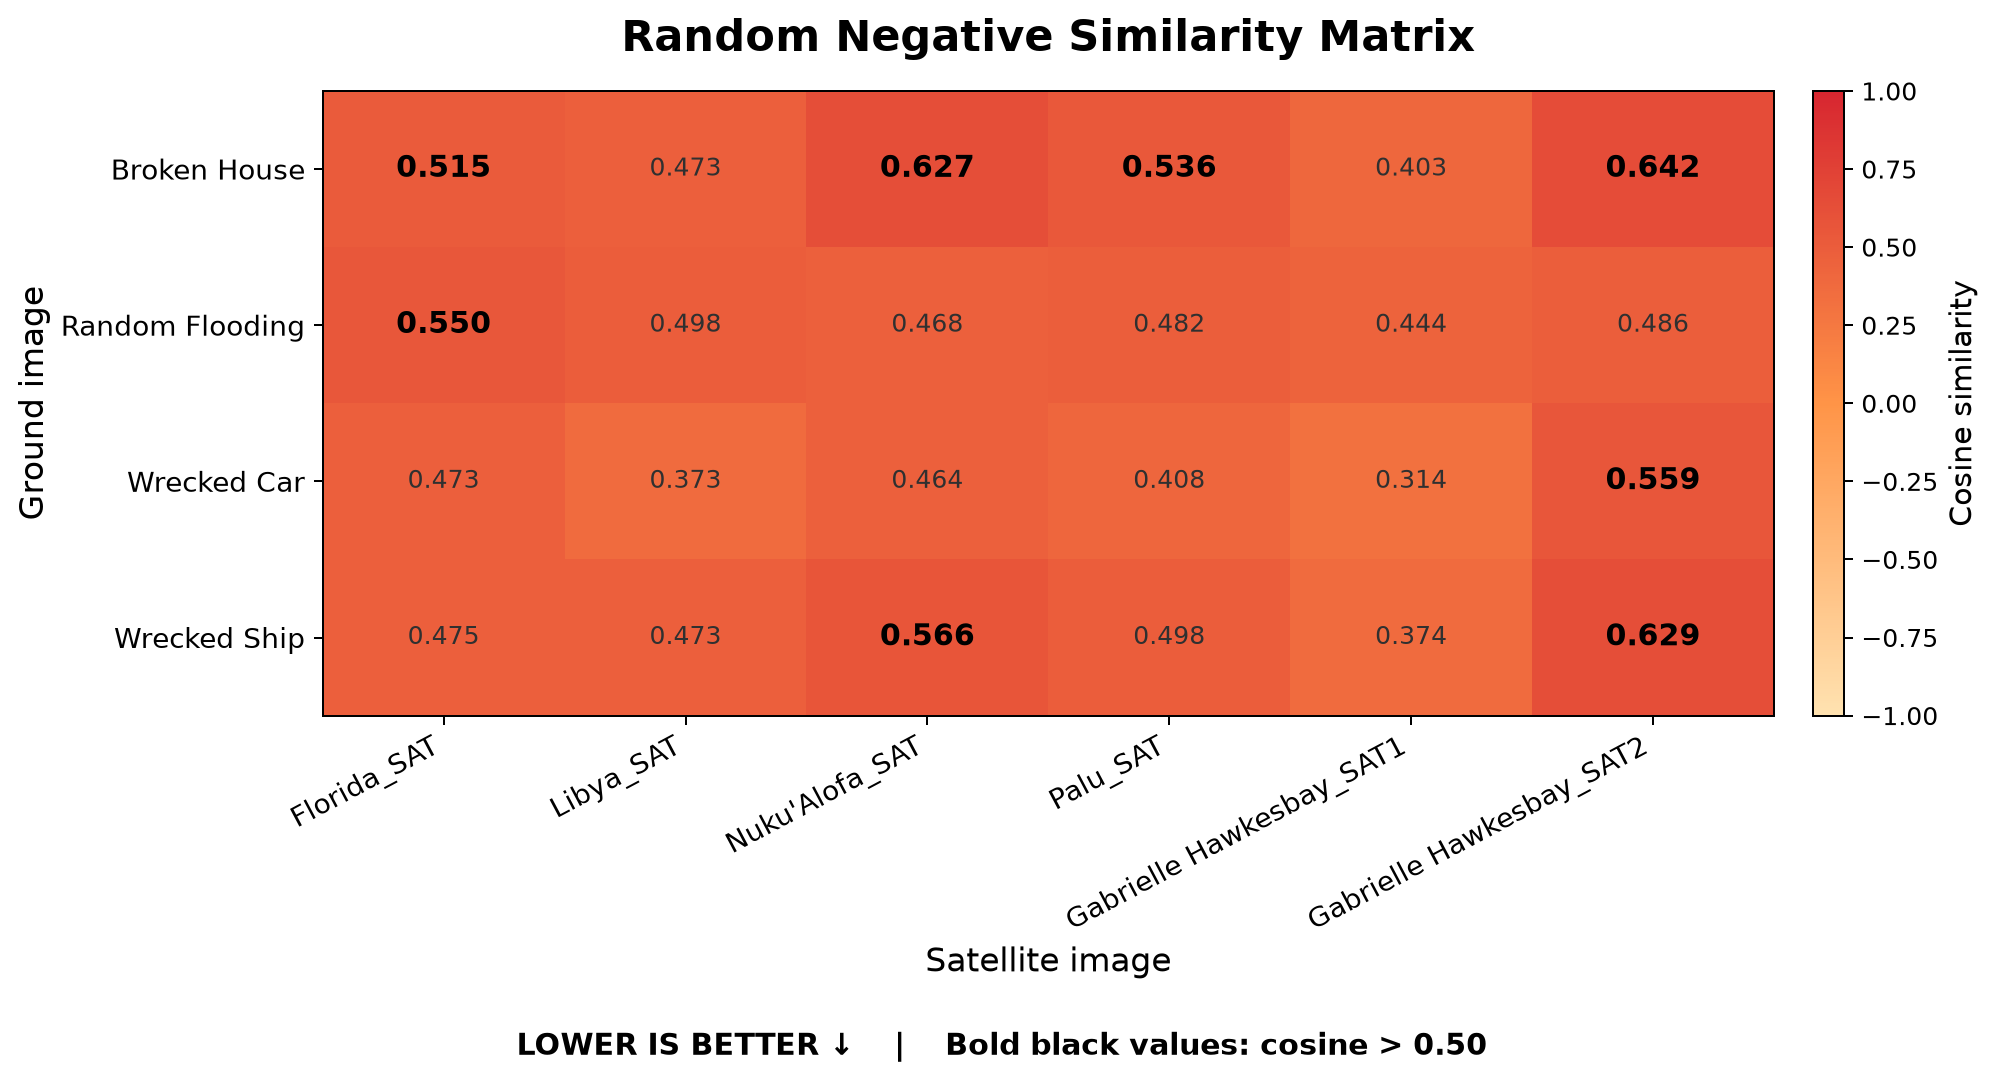

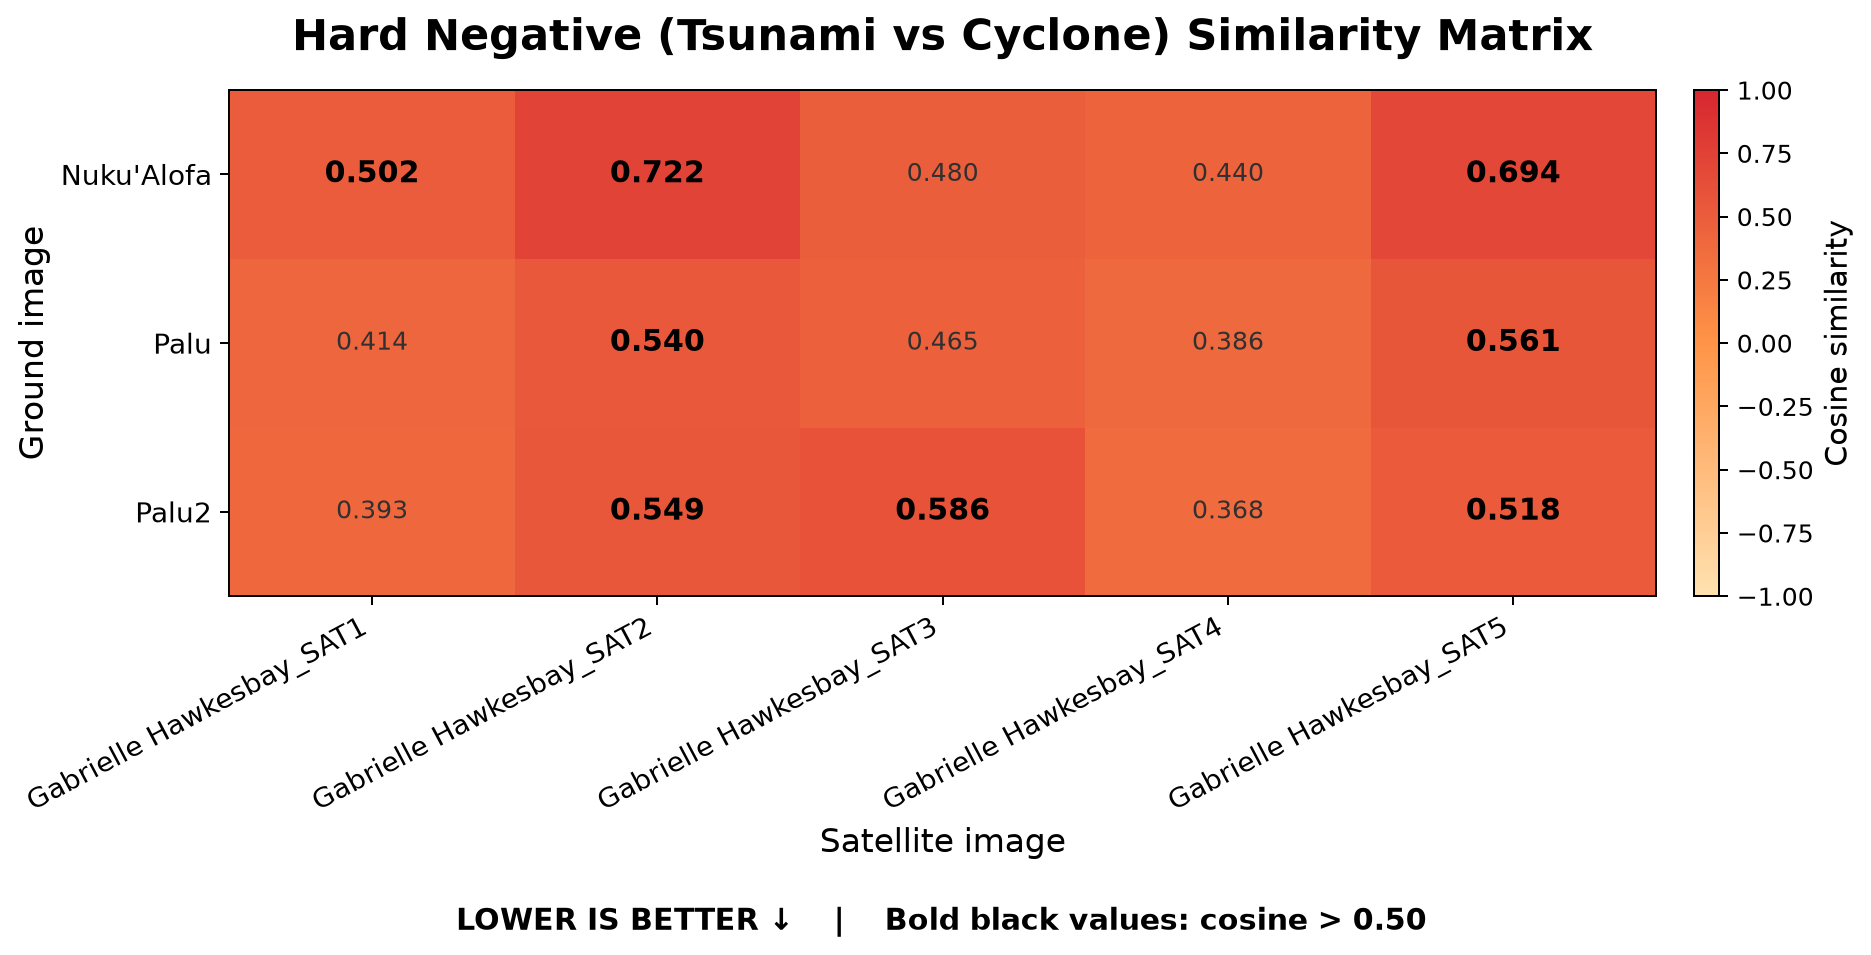

In [32]:
POSITIVE_CMAP = LinearSegmentedColormap.from_list(
    "yellow_to_green",
    ["#fff176", "#c8ff66", "#00d76f"],
)
NEGATIVE_CMAP = LinearSegmentedColormap.from_list(
    "orange_to_red",
    ["#ffe2b0", "#ff9447", "#d72630"],
)
# Fix the scale for every matrix. Warm/high scores indicate a worse negative match.
COLOR_MIN, COLOR_MAX = -1.0, 1.0


def prettify_matrix_label(filename):
    """
    Remove disaster prefixes from display labels while
    preserving the original _SAT, _SAT1, _SAT2, etc.
    """

    label = Path(filename).stem

    # Remove repeated disaster prefixes
    label = re.sub(
        r"^(FLOODING|TSUNAMI)[_\s-]+",
        "",
        label,
        flags=re.IGNORECASE
    )

    # Preserve the original satellite suffix
    match = re.search(
        r"(_SAT(?:ELLITE)?\d*)$",
        label,
        flags=re.IGNORECASE
    )

    sat_suffix = match.group(1) if match else ""

    if match:
        label = label[:match.start()]

    # Make the remaining label readable
    label = re.sub(r"[_-]+", " ", label)
    label = re.sub(r"\s+", " ", label).strip()
    label = label.title()

    return label + sat_suffix


def plot_similarity_matrix(raw_df, model_key, group_name):
    group = EVALUATION_GROUPS[group_name]
    subset = raw_df.loc[
        (raw_df["model_key"] == model_key)
        & (raw_df["query_type"] == group_name)
    ]

    # Index by full path internally (not filename) to avoid duplicates.
    pivot = subset.pivot(
        index="ground_path", columns="satellite_image", values="cosine_similarity"
    )
    expected_rows = [str(p) for p in group["ground_paths"]]
    expected_cols = [p.name for p in group["satellite_paths"]]
    values = pivot.reindex(index=expected_rows, columns=expected_cols).to_numpy(dtype=float)

    if np.isnan(values).any():
        raise ValueError(f"Missing similarity scores for {model_key} / {group_name}")

    is_positive = group["is_positive"]
    nrows, ncols = values.shape
    width = max(11, 1.20 * ncols + 4.5)
    height = max(4.5, 0.70 * nrows + 3.2)
    fig, ax = plt.subplots(figsize=(width, height))

    cmap = POSITIVE_CMAP if is_positive else NEGATIVE_CMAP
    image = ax.imshow(values, cmap=cmap, vmin=COLOR_MIN, vmax=COLOR_MAX, aspect="auto")

    row_labels = [prettify_matrix_label(p.name) for p in group["ground_paths"]]
    col_labels = [prettify_matrix_label(name) for name in expected_cols]

    ax.set_xticks(range(ncols))
    ax.set_xticklabels(col_labels, rotation=28, ha="right", fontsize=11)
    ax.set_yticks(range(nrows))
    ax.set_yticklabels(row_labels, fontsize=11)
    ax.set_xlabel("Satellite image", fontsize=13)
    ax.set_ylabel("Ground image", fontsize=13)
    figure_title = (
        "Hard Negative (Tsunami vs Cyclone) Similarity Matrix"
        if group_name == "Hard Negative"
        else f"{group_name} Similarity Matrix"
    )

    ax.set_title(
        figure_title,
        fontsize=17, pad=16, weight="semibold",
    )

    for i in range(nrows):
        for j in range(ncols):
            score = values[i, j]
            above_threshold = score > COSINE_THRESHOLD
            ax.text(
                j, i, f"{score:.3f}",
                ha="center", va="center",
                fontsize=12 if above_threshold else 10,
                weight="bold" if above_threshold else "normal",
                color="#000000" if above_threshold else "#303030",
            )

    colorbar = fig.colorbar(image, ax=ax, fraction=0.035, pad=0.025)
    colorbar.set_label("Cosine similarity", fontsize=12)

    direction_text = "HIGHER IS BETTER ↑" if is_positive else "LOWER IS BETTER ↓"
    fig.text(
        0.5, 0.005,
        f"{direction_text}    |    Bold black values: cosine > {COSINE_THRESHOLD:.2f}",
        ha="center", fontsize=12, weight="bold",
    )
    fig.tight_layout(rect=[0.02, 0.05, 0.98, 0.99])

    if SAVE_FIGURES:
        safe_name = group_name.lower().replace(" ", "_")
        fig.savefig(
            FIGURE_OUTPUT_DIR / f"{model_key}_{safe_name}_similarity_matrix.png",
            dpi=300, bbox_inches="tight",
        )
    plt.show()


for model_key in ACTIVE_MODEL_KEYS:
    for group_name in FIGURE_ORDER:
        plot_similarity_matrix(similarity_raw, model_key, group_name)



# 8. Compute threshold-based outcomes for the **selected comparisons only**

On negative groups, any score above 0.5 is an FP. On positive groups, the overall acceptance rate is computed for all same-category candidate comparisons. A full TP/FP/TN/FN confusion matrix is computed **only for ground photos with a verified corresponding satellite file**, using filename/manual mapping from Section 5.

In [33]:
def classify_selected_pairs(raw_df, threshold=0.50):
    rows = []
    for _, row in raw_df.iterrows():
        group_name = row["query_type"]
        predicted_match = bool(row["cosine_similarity"] > threshold)
        verified = False
        actual_match = None
        outcome = "ACCEPTED" if predicted_match else "REJECTED"

        if group_name in NEGATIVE_TYPES:
            verified = True
            actual_match = False
            outcome = "FP" if predicted_match else "TN"

        else:
            key = (group_name, row["ground_path"])
            known_matches = MATCHED_POSITIVE_SATELLITES[key]
            if known_matches:
                verified = True
                actual_match = row["satellite_image"] in known_matches
                if actual_match and predicted_match:
                    outcome = "TP"
                elif actual_match and not predicted_match:
                    outcome = "FN"
                elif not actual_match and predicted_match:
                    outcome = "FP"
                else:
                    outcome = "TN"
            else:
                outcome = "UNVERIFIED"

        rows.append({
            **row.to_dict(),
            "predicted_match": predicted_match,
            "verified_actual": verified,
            "actual_match": actual_match,
            "outcome": outcome,
        })
    return pd.DataFrame(rows)


classified_pairs = classify_selected_pairs(similarity_raw, COSINE_THRESHOLD)
print("Pair-level classification sample:")
display(classified_pairs.head())

Pair-level classification sample:


,model_key,model_label,query_type,ground_path,ground_image,satellite_image,cosine_similarity,is_positive_group,predicted_match,verified_actual,actual_match,outcome
0,transgeo,TransGeo Fine-Tuned,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_FLORIDA_SAT.jpeg,0.536072,True,True,True,True,TP
1,transgeo,TransGeo Fine-Tuned,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_LIBYA_SAT.jpeg,0.464224,True,False,True,False,TN
2,transgeo,TransGeo Fine-Tuned,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_LUGANVILLE_SAT.jpeg,0.551065,True,True,True,False,FP
3,transgeo,TransGeo Fine-Tuned,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_FLORIDA.jpg,FLOODING_NATHAMAKI_SAT.jpeg,0.479808,True,False,True,False,TN
4,transgeo,TransGeo Fine-Tuned,Flood,E:\python_project\Geo\Test_ground_image\Flood\...,FLOODING_LIBYA.jpeg,FLOODING_FLORIDA_SAT.jpeg,0.557137,True,True,True,False,FP


# 9. Positive disaster-category scores

**Positive acceptance rate** is the proportion of within-category comparisons with cosine > 0.5. It is not necessarily geographic-match recall because same-disaster images can depict different locations. A filename-verified **precision/confusion matrix** is shown separately in the next section.

In [34]:
positive_summary_rows = []
for model_key in ACTIVE_MODEL_KEYS:
    for category in POSITIVE_CATEGORIES:
        subset = classified_pairs.loc[
            (classified_pairs["model_key"] == model_key)
            & (classified_pairs["query_type"] == category)
        ]
        accepted_rate = 100 * subset["predicted_match"].mean()
        verified_subset = subset.loc[subset["verified_actual"]]
        positive_summary_rows.append({
            "Model": MODEL_REGISTRY[model_key]["label"],
            "Disaster": category,
            "Category acceptance %": round(accepted_rate, 1),
            "Pair comparisons": len(subset),
            "Verified pair comparisons": len(verified_subset),
        })
positive_acceptance_summary = pd.DataFrame(positive_summary_rows)
display(positive_acceptance_summary)

,Model,Disaster,Category acceptance %,Pair comparisons,Verified pair comparisons
0,TransGeo Fine-Tuned,Flood,50.0,16,16
1,TransGeo Fine-Tuned,Tsunami,77.8,9,6
2,TransGeo Fine-Tuned,Cyclone,52.0,25,25


# 10. Positive filename-verified confusion matrices

Only pairs with ground-truth names verified in Section 5 count toward the confusion matrix and **Precision = TP / (TP + FP)**. If none have matching filenames, precision is reported as **N/A**, not incorrectly as zero. Each enabled model gets a confusion figure and precision summary per disaster with usable verified pairs.

Verified positive-pair confusion summary:


,model_key,Model,Disaster,TP,FP,TN,FN,Precision %,Verified pairs
0,transgeo,TransGeo Fine-Tuned,Flood,2,6,6,2,25.000000,16
1,transgeo,TransGeo Fine-Tuned,Tsunami,1,3,0,2,25.000000,6
2,transgeo,TransGeo Fine-Tuned,Cyclone,4,9,11,1,30.769231,25


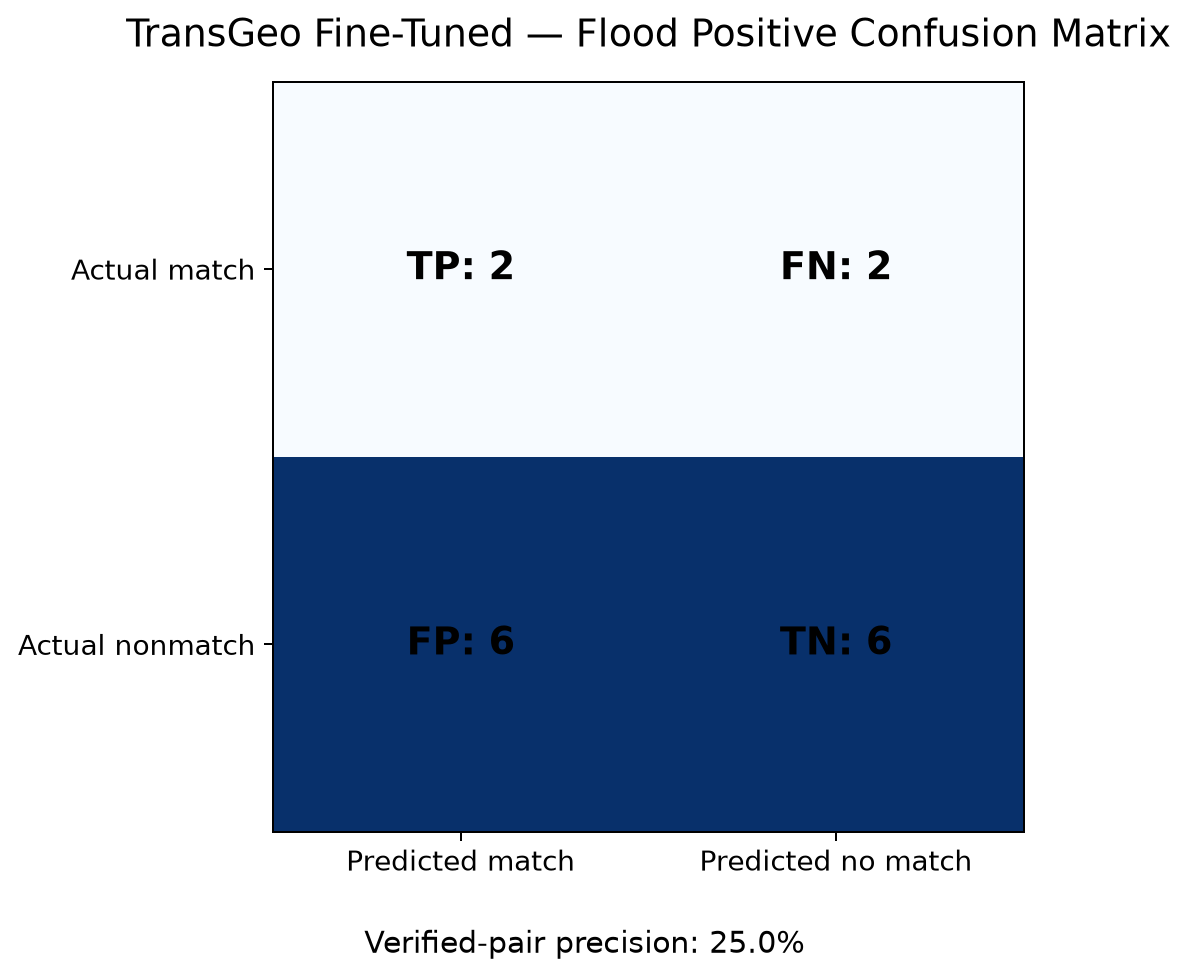

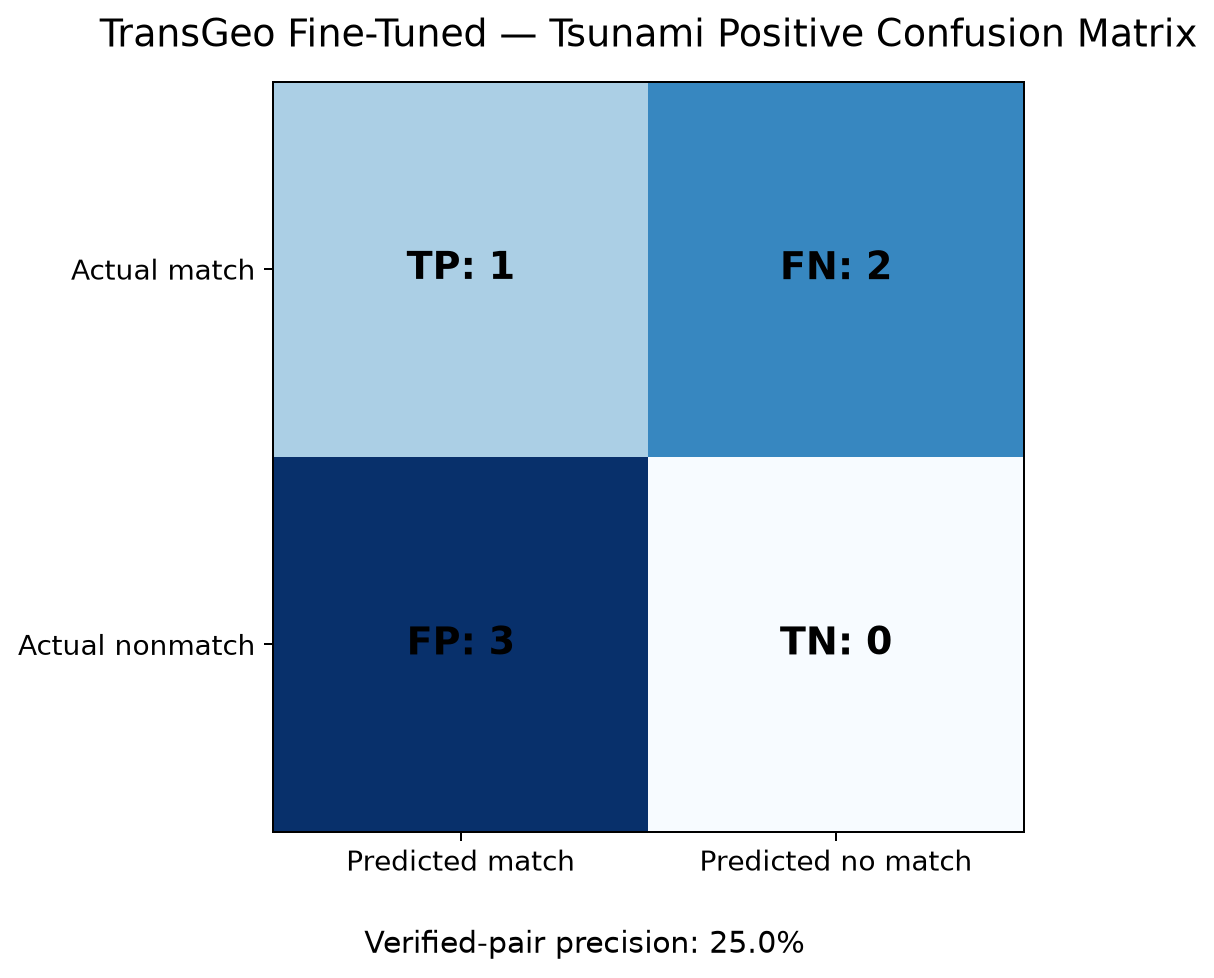

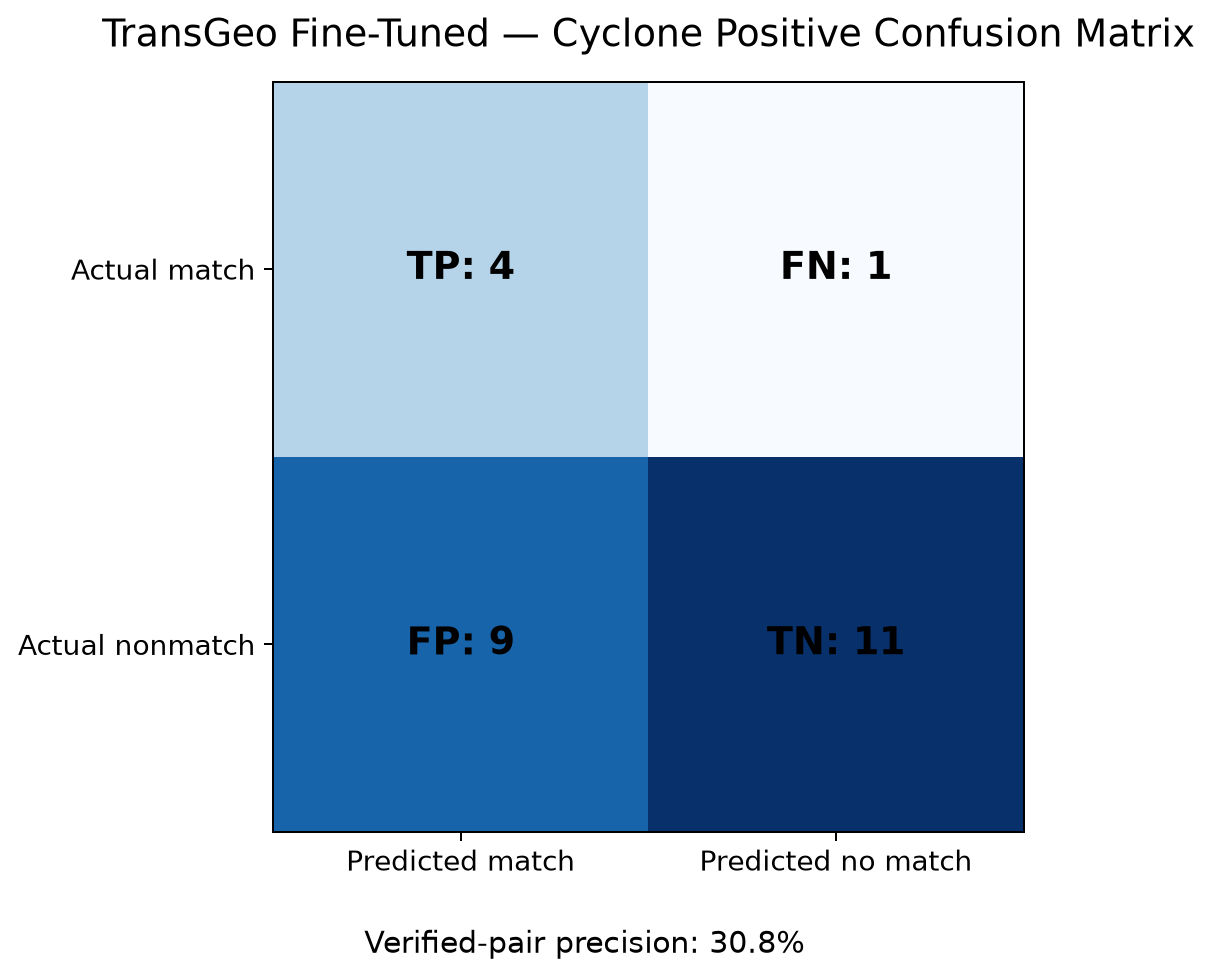

In [35]:
def summarize_filename_verified_positives(df):
    rows = []
    for model_key in ACTIVE_MODEL_KEYS:
        for category in POSITIVE_CATEGORIES:
            subset = df.loc[
                (df["model_key"] == model_key)
                & (df["query_type"] == category)
                & (df["verified_actual"])
            ]
            counts = {name: int((subset["outcome"] == name).sum())
                      for name in ["TP", "FP", "TN", "FN"]}
            denominator = counts["TP"] + counts["FP"]
            precision = 100 * counts["TP"] / denominator if denominator else np.nan
            rows.append({
                "model_key": model_key,
                "Model": MODEL_REGISTRY[model_key]["label"],
                "Disaster": category,
                **counts,
                "Precision %": precision,
                "Verified pairs": len(subset),
            })
    return pd.DataFrame(rows)


positive_confusion_summary = summarize_filename_verified_positives(classified_pairs)
print("Verified positive-pair confusion summary:")
display(positive_confusion_summary)


def plot_positive_confusion(row):
    if row["Verified pairs"] == 0:
        print("Skipping confusion figure:", row["Model"], row["Disaster"], "(no verified name matches)")
        return
    # Rows = actual match / actual nonmatch; columns = predicted match / predicted nonmatch.
    counts = np.array([[row["TP"], row["FN"]], [row["FP"], row["TN"]]], dtype=int)
    fig, ax = plt.subplots(figsize=(7.2, 5.4))
    image = ax.imshow(counts, cmap="Blues")
    ax.set_xticks([0, 1], labels=["Predicted match", "Predicted no match"], fontsize=11)
    ax.set_yticks([0, 1], labels=["Actual match", "Actual nonmatch"], fontsize=11)
    labels = [["TP", "FN"], ["FP", "TN"]]
    for i in range(2):
        for j in range(2):
            # Construct label with two calls instead of embedding a newline escape.
            ax.text(j, i, f"{labels[i][j]}: {counts[i, j]}",
                    ha="center", va="center", fontsize=15, weight="bold")
    precision_text = "N/A" if pd.isna(row["Precision %"]) else f"{row['Precision %']:.1f}%"
    ax.set_title(f"{row['Model']} — {row['Disaster']} Positive Confusion Matrix",
                 fontsize=15, pad=14)
    fig.text(0.5, 0.01, f"Verified-pair precision: {precision_text}", ha="center", fontsize=12)
    fig.tight_layout(rect=[0, 0.06, 1, 1])
    if SAVE_FIGURES:
        fig.savefig(FIGURE_OUTPUT_DIR / f"{row['model_key']}_{row['Disaster'].lower()}_positive_confusion.png",
                    dpi=300, bbox_inches="tight")
    plt.show()


for _, summary_row in positive_confusion_summary.iterrows():
    plot_positive_confusion(summary_row)

# 11. Negative-set FPR — simple percentage table

FALSE POSITIVE RATE (LOWER IS BETTER)


,Model,Type,FPR %
0,TransGeo Fine-Tuned,Easy Negative,0.0%
1,TransGeo Fine-Tuned,Random Negative,33.3%
2,TransGeo Fine-Tuned,Hard Negative,53.3%


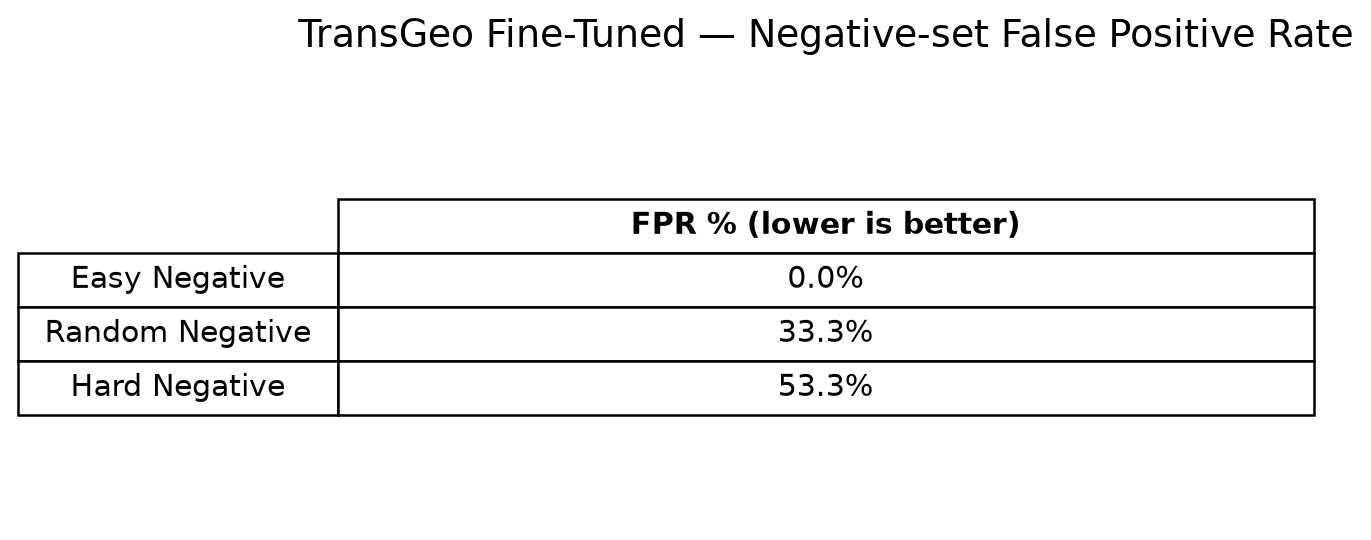

In [36]:
fpr_rows = []
for model_key in ACTIVE_MODEL_KEYS:
    for group_name in NEGATIVE_TYPES:
        subset = classified_pairs.loc[
            (classified_pairs["model_key"] == model_key)
            & (classified_pairs["query_type"] == group_name)
        ]
        fp = int((subset["outcome"] == "FP").sum())
        tn = int((subset["outcome"] == "TN").sum())
        fpr = 100 * fp / (fp + tn) if (fp + tn) else np.nan
        fpr_rows.append({
            "Model": MODEL_REGISTRY[model_key]["label"],
            "Type": group_name,
            "FPR %": fpr,
        })

negative_fpr_summary = pd.DataFrame(fpr_rows)
print("FALSE POSITIVE RATE (LOWER IS BETTER)")
display(negative_fpr_summary.style.format({"FPR %": "{:.1f}%"}))

# Publication-friendly percent-only table for each selected model.
for model_key in ACTIVE_MODEL_KEYS:
    label = MODEL_REGISTRY[model_key]["label"]
    subset = negative_fpr_summary.loc[negative_fpr_summary["Model"] == label]
    cell_text = [["N/A" if pd.isna(v) else f"{v:.1f}%"] for v in subset["FPR %"]]
    fig, ax = plt.subplots(figsize=(7.5, 3.1))
    ax.axis("off")
    table = ax.table(
        cellText=cell_text,
        rowLabels=subset["Type"].tolist(),
        colLabels=["FPR % (lower is better)"],
        cellLoc="center", rowLoc="center", loc="center",
    )
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(1.0, 1.8)
    table[0, 0].set_text_props(weight="bold")
    ax.set_title(f"{label} — Negative-set False Positive Rate", fontsize=15, pad=18)
    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(FIGURE_OUTPUT_DIR / f"{model_key}_negative_fpr_table.png", dpi=300, bbox_inches="tight")
    plt.show()

# 12. Optional: see exactly which negative pairs exceed the 0.50 threshold

In [37]:
negative_false_positives = classified_pairs.loc[
    (classified_pairs["query_type"].isin(NEGATIVE_TYPES))
    & (classified_pairs["outcome"] == "FP")
].sort_values(["model_label", "query_type", "cosine_similarity"], ascending=[True, True, False])

print("Incorrectly accepted negative pairs:")
display(negative_false_positives[
    ["model_label", "query_type", "ground_image", "satellite_image", "cosine_similarity"]
])

Incorrectly accepted negative pairs:


,model_label,query_type,ground_image,satellite_image,cosine_similarity
99,TransGeo Fine-Tuned,Hard Negative,TSUNAMI_NUKU'ALOFA.jpg,GABRIELLE_HAWKESBAY_SAT2.png,0.721592
102,TransGeo Fine-Tuned,Hard Negative,TSUNAMI_NUKU'ALOFA.jpg,GABRIELLE_HAWKESBAY_SAT5.png,0.693804
110,TransGeo Fine-Tuned,Hard Negative,TSUNAMI_PALU2.jpeg,GABRIELLE_HAWKESBAY_SAT3.png,0.586356
107,TransGeo Fine-Tuned,Hard Negative,TSUNAMI_PALU.jpg,GABRIELLE_HAWKESBAY_SAT5.png,0.561011
109,TransGeo Fine-Tuned,Hard Negative,TSUNAMI_PALU2.jpeg,GABRIELLE_HAWKESBAY_SAT2.png,0.548561
104,TransGeo Fine-Tuned,Hard Negative,TSUNAMI_PALU.jpg,GABRIELLE_HAWKESBAY_SAT2.png,0.539996
112,TransGeo Fine-Tuned,Hard Negative,TSUNAMI_PALU2.jpeg,GABRIELLE_HAWKESBAY_SAT5.png,0.518356
98,TransGeo Fine-Tuned,Hard Negative,TSUNAMI_NUKU'ALOFA.jpg,GABRIELLE_HAWKESBAY_SAT1.png,0.501717
79,TransGeo Fine-Tuned,Random Negative,broken_house.jpg,GABRIELLE_HAWKESBAY_SAT2.png,0.641652
97,TransGeo Fine-Tuned,Random Negative,wrecked_ship.jpg,GABRIELLE_HAWKESBAY_SAT2.png,0.629439


# 13. Optional: export report-ready numeric results

This cell writes **raw pairwise scores**, verified positive confusion summaries, and negative-set FPRs to CSV for the final report. It does not recalculate or change the visual outputs. CSV exports are disabled by default, matching the benchmark's default figure-saving behaviour.


In [38]:
EXPORT_CSV = False
if EXPORT_CSV:
    FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    similarity_raw.to_csv(FIGURE_OUTPUT_DIR / "transgeo_pairwise_similarity.csv", index=False)
    classified_pairs.to_csv(FIGURE_OUTPUT_DIR / "transgeo_pairwise_classification.csv", index=False)
    positive_acceptance_summary.to_csv(FIGURE_OUTPUT_DIR / "transgeo_positive_acceptance.csv", index=False)
    positive_confusion_summary.to_csv(FIGURE_OUTPUT_DIR / "transgeo_positive_confusion.csv", index=False)
    negative_fpr_summary.to_csv(FIGURE_OUTPUT_DIR / "transgeo_negative_fpr.csv", index=False)
    print("Evaluation CSV files saved to:", FIGURE_OUTPUT_DIR)
else:
    print("CSV export disabled. Set EXPORT_CSV = True to write report tables.")


CSV export disabled. Set EXPORT_CSV = True to write report tables.
